In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from scipy.integrate import solve_ivp
import pandas as pd
from scipy.optimize import brentq


## Modelo da Teoria de Modos Acoplados.

RAMZI é um MZI, cujo um dos braços é composto por um micro-ring resonator (MRR). Podemos escrever a dinâmica do (MRR) com a amplitude de luz, **$a$**, e a densidade de portadores **$N_c$**:

\begin{equation}
\frac{da}{dt} = - \left(j\Delta\omega + \gamma_L\right)a - j\eta_{fc}N_{c}a - j\mu\sqrt{P_{in}}
\end{equation}

\begin{equation}
\frac{dN_c}{dt} + \frac{N_c}{\tau_{fc}} = \xi |a|^4
\end{equation}


Dúvida 1: Qual o valor de cada parâmetro do sistema de EDOs? É muito falado sobre a referência 20, mas não consigo acessar ela.

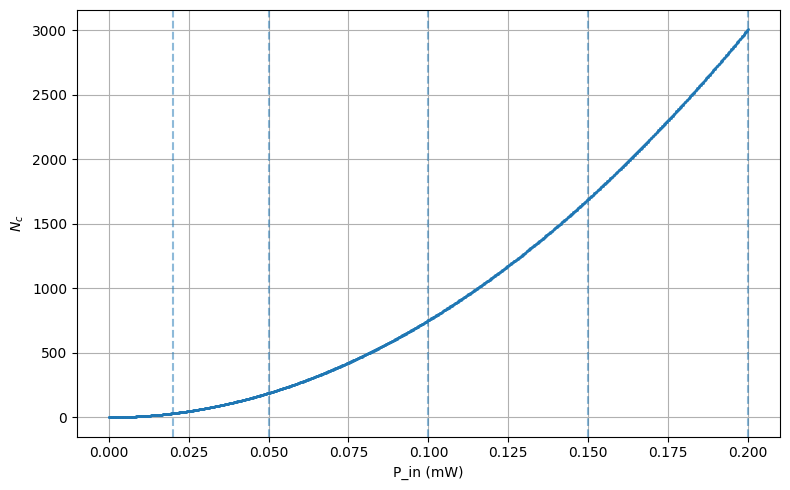

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\3264854309.py:44: RuntimeWarning: overflow encountered in scalar power
  I = abs(a)**2
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\3264854309.py:49: RuntimeWarning: overflow encountered in scalar multiply
  -(gamma + 1j*delta_eff)*a
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\3264854309.py:53: RuntimeWarning: overflow encountered in scalar power
  dNc = -Nc/tau + xi*I**2
c:\Users\erick.sousa\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\integrate\_ivp\rk.py:63: RuntimeWarning: invalid value encountered in dot
  dy = np.dot(K[:s].T, a[:s]) * h
c:\Users\erick.sousa\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\integrate\_ivp\rk.py:66: RuntimeWarning: invalid value encountered in dot
  y_new = y + h * np.dot(K[:-1].T, B)
c:\Users\erick.sousa\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\integrate\_ivp\rk.py:684: RuntimeWarning: invalid value encountered in 

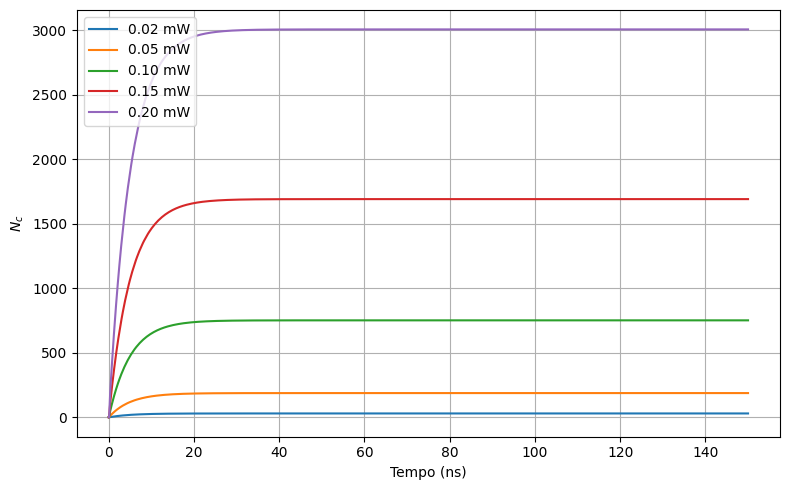



VALIDAÇÃO DO MODELO


P = 0.020 mW
Número de raízes = 1

--- Raiz estacionária escolhida ---
I_root  = 7.754532734783e-16
Nc_root = 3.006638896741e+01

--- Resultado da ODE ---
I_ode   = 7.754532734645e-16
Nc_ode  = 3.006638896740e+01

--- Erros ODE vs raiz ---
Erro relativo I  = 1.782534e-11
Erro relativo Nc = 4.155768e-13

--- Resíduo equação estacionária ---
F(I_root) = 0.000000e+00
F(I_ode)  = -3.565045e-06
Resíduo relativo raiz = 0.000000e+00
Resíduo relativo ODE  = 1.782522e-11

--- Equação dos portadores ---
Resíduo relativo dNc/dt = 3.523500e-11

--- Derivadas no final da ODE ---
|da/dt| = 8.770712e-09
|dNc/dt| = 2.118778e-01


P = 0.050 mW
Número de raízes = 1

--- Raiz estacionária escolhida ---
I_root  = 1.938633183696e-15
Nc_root = 1.879149310463e+02

--- Resultado da ODE ---
I_ode   = 1.938633183701e-15
Nc_ode  = 1.879149310463e+02

--- Erros ODE vs raiz ---
Erro relativo I  = 2.535494e-12
Erro relativo Nc = 1.099571e-13

--- Resíduo equação estacionária ---
F(I_root) = 

In [2]:


# ============================================================
# PARÂMETROS
# ============================================================

lambda0 = 1550e-9
delta = 2 * np.pi * 2e9

gamma = 1e10 
eta_fc = 4e-6 # Apenas um RAMZI

eta_fc = 1e-6 # Para o D-RAMZI completo
tau = 5e-9 
xi = 1e40 
mu = 1e5

P_vec = np.linspace(0, 0.2e-3, 1000)


# ============================================================
# ESCALA PARA A INTENSIDADE
#
# Os valores de I são ~ 10^-14.
# Trabalhamos internamente com:
#
#       x = I / I_scale
#
# onde I_scale = 10^-14.
# ============================================================

I_scale = 1e-14


# ============================================================
# MODELO DINÂMICO
#
# y = [Re(a), Im(a), Nc]
# ============================================================

def model(t, y, P):

    a = y[0] + 1j*y[1]
    Nc = y[2]

    I = abs(a)**2

    delta_eff = delta + eta_fc*Nc

    da = (
        -(gamma + 1j*delta_eff)*a
        - 1j*mu*np.sqrt(P)
    )

    dNc = -Nc/tau + xi*I**2

    return [
        da.real,
        da.imag,
        dNc
    ]


# ============================================================
# EQUAÇÃO ESTACIONÁRIA
#
# No estado estacionário:
#
#     Nc = tau * xi * I^2
#
# e
#
#     I [gamma^2 + delta_eff^2] = mu^2 P
#
# ============================================================

def F_raw(I, P):

    if P == 0:
        return I

    Nc = tau * xi * I**2

    delta_eff = delta + eta_fc*Nc

    return (
        I * (
            gamma**2 +
            delta_eff**2
        )
        - mu**2 * P
    )


# ============================================================
# EQUAÇÃO ESTACIONÁRIA ESCALADA
#
# x = I / I_scale
# I = x * I_scale
# ============================================================

def F_scaled(x, P):

    I = x * I_scale

    return F_raw(I, P)


# ============================================================
# TODAS AS RAÍZES ESTACIONÁRIAS
# ============================================================

def roots(P):

    if P == 0:
        return [0.0]

    # Faixa ampla em x, não diretamente em I
    x_grid = np.logspace(-8, 8, 10000)

    values = np.array([
        F_scaled(x, P)
        for x in x_grid
    ])

    roots_found = []

    for i in range(len(x_grid) - 1):

        f1 = values[i]
        f2 = values[i + 1]

        # Raiz exatamente em um ponto
        if f1 == 0:
            roots_found.append(x_grid[i] * I_scale)

        # Mudança de sinal
        elif f1 * f2 < 0:

            x_root = brentq(
                lambda x: F_scaled(x, P),
                x_grid[i],
                x_grid[i + 1],
                xtol=1e-12,
                rtol=1e-14
            )

            I_root = x_root * I_scale

            roots_found.append(I_root)

    # Remove possíveis duplicatas numéricas
    roots_found = np.array(sorted(roots_found))

    if len(roots_found) == 0:
        return []

    unique_roots = [roots_found[0]]

    for r in roots_found[1:]:

        if abs(r - unique_roots[-1]) > 1e-10 * max(abs(r), 1e-30):
            unique_roots.append(r)

    return unique_roots


# ============================================================
# ESTADOS ESTACIONÁRIOS
# ============================================================

P_ss = []
I_ss = []
Nc_ss = []

for P in P_vec:

    for I in roots(P):

        Nc = tau * xi * I**2

        P_ss.append(P)
        I_ss.append(I)
        Nc_ss.append(Nc)


P_ss = np.array(P_ss)
I_ss = np.array(I_ss)
Nc_ss = np.array(Nc_ss)


# ============================================================
# GRÁFICO: N_c ESTACIONÁRIO
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    P_ss * 1e3,
    Nc_ss,
    '.',
    markersize=2
)

for p in [0.02, 0.05, 0.10, 0.15, 0.20]:
    plt.axvline(p, linestyle='--', alpha=0.5)

plt.xlabel("P_in (mW)")
plt.ylabel(r"$N_c$")
plt.grid()

plt.tight_layout()
plt.show()


# ============================================================
# SIMULAÇÃO TEMPORAL
# ============================================================

P_test = [
    0.02e-3,
    0.05e-3,
    0.10e-3,
    0.15e-3,
    0.20e-3
]


plt.figure(figsize=(8, 5))

for P in P_test:

    sol = solve_ivp(
        lambda t, y: model(t, y, P),
        (0, 150e-9),             # 1 microsegundo
        [0.0, 0.0, 0.0],

        rtol=1e-9,
        atol=[
            1e-20,             # Re(a)
            1e-20,             # Im(a)
            1e-14              # Nc
        ],

        method="DOP853"
    )

    a = sol.y[0] + 1j*sol.y[1]

    Nc = sol.y[2]

    plt.plot(
        sol.t * 1e9,
        Nc,
        label=f"{P*1e3:.2f} mW"
    )


plt.xlabel("Tempo (ns)")
plt.ylabel(r"$N_c$")
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# TESTE / VALIDAÇÃO
# ============================================================

print("\n")
print("="*70)
print("VALIDAÇÃO DO MODELO")
print("="*70)


for P in P_test:

    # --------------------------------------------------------
    # 1. Encontrar raiz estacionária
    # --------------------------------------------------------

    r = roots(P)

    print("\n")
    print(f"P = {P*1e3:.3f} mW")
    print(f"Número de raízes = {len(r)}")

    if len(r) == 0:
        print("Nenhuma raiz encontrada.")
        continue


    # --------------------------------------------------------
    # 2. Resolver ODE
    # --------------------------------------------------------

    sol = solve_ivp(
        lambda t, y: model(t, y, P),
        (0, 1e-6),
        [0.0, 0.0, 0.0],

        rtol=1e-9,
        atol=[
            1e-20,
            1e-20,
            1e-14
        ],

        method="DOP853"
    )


    a_final = sol.y[0, -1] + 1j*sol.y[1, -1]

    I_ode = abs(a_final)**2
    Nc_ode = sol.y[2, -1]


    # --------------------------------------------------------
    # 3. Comparar ODE com todas as raízes
    # --------------------------------------------------------

    distances = [
        abs(I_root - I_ode)
        for I_root in r
    ]

    index = np.argmin(distances)

    I_root = r[index]
    Nc_root = tau * xi * I_root**2


    # --------------------------------------------------------
    # 4. Erros relativos
    # --------------------------------------------------------

    error_I = abs(I_ode - I_root) / max(abs(I_root), 1e-30)

    error_Nc = abs(Nc_ode - Nc_root) / max(abs(Nc_root), 1e-30)


    # --------------------------------------------------------
    # 5. Resíduos da equação estacionária
    # --------------------------------------------------------

    residual_root = F_raw(I_root, P)

    residual_ode = F_raw(I_ode, P)

    residual_root_rel = abs(residual_root) / (mu**2 * P)

    residual_ode_rel = abs(residual_ode) / (mu**2 * P)


    # --------------------------------------------------------
    # 6. Resíduo da equação dos portadores
    # --------------------------------------------------------

    carrier_residual_ode = (
        -Nc_ode/tau
        + xi*I_ode**2
    )

    carrier_residual_rel = (
        abs(carrier_residual_ode)
        /
        max(abs(Nc_ode/tau), 1e-30)
    )


    # --------------------------------------------------------
    # 7. Derivadas finais da ODE
    # --------------------------------------------------------

    dy_final = model(
        sol.t[-1],
        sol.y[:, -1],
        P
    )

    derivative_a = np.sqrt(
        dy_final[0]**2 +
        dy_final[1]**2
    )

    derivative_Nc = abs(dy_final[2])


    # --------------------------------------------------------
    # RESULTADOS
    # --------------------------------------------------------

    print("\n--- Raiz estacionária escolhida ---")

    print(f"I_root  = {I_root:.12e}")
    print(f"Nc_root = {Nc_root:.12e}")

    print("\n--- Resultado da ODE ---")

    print(f"I_ode   = {I_ode:.12e}")
    print(f"Nc_ode  = {Nc_ode:.12e}")

    print("\n--- Erros ODE vs raiz ---")

    print(f"Erro relativo I  = {error_I:.6e}")
    print(f"Erro relativo Nc = {error_Nc:.6e}")

    print("\n--- Resíduo equação estacionária ---")

    print(f"F(I_root) = {residual_root:.6e}")
    print(f"F(I_ode)  = {residual_ode:.6e}")

    print(f"Resíduo relativo raiz = {residual_root_rel:.6e}")
    print(f"Resíduo relativo ODE  = {residual_ode_rel:.6e}")

    print("\n--- Equação dos portadores ---")

    print(
        f"Resíduo relativo dNc/dt = "
        f"{carrier_residual_rel:.6e}"
    )

    print("\n--- Derivadas no final da ODE ---")

    print(f"|da/dt| = {derivative_a:.6e}")
    print(f"|dNc/dt| = {derivative_Nc:.6e}")


# ============================================================
# TESTE EXTRA: CONSISTÊNCIA ALGÉBRICA
# ============================================================

print("\n")
print("="*70)
print("TESTE ALGÉBRICO DIRETO PARA P = 0.2 mW")
print("="*70)

P = 0.2e-3

r = roots(P)

if len(r) > 0:

    for k, I in enumerate(r):

        Nc = tau * xi * I**2

        delta_eff = delta + eta_fc*Nc

        lhs = (
            I *
            (
                gamma**2 +
                delta_eff**2
            )
        )

        rhs = mu**2 * P

        relative_error = abs(lhs-rhs)/rhs

        print(f"\nRaiz {k+1}")

        print(f"I       = {I:.12e}")
        print(f"Nc      = {Nc:.12e}")
        print(f"delta_eff = {delta_eff:.12e}")

        print(f"LHS     = {lhs:.12e}")
        print(f"RHS     = {rhs:.12e}")

        print(f"LHS-RHS = {lhs-rhs:.12e}")

        print(
            f"Erro relativo = "
            f"{relative_error:.6e}"
        )

        # Verificação independente da equação dos portadores

        Nc_expected = tau * xi * I**2

        print(
            f"Erro Nc = "
            f"{abs(Nc-Nc_expected):.6e}"
        )

## FUNÇÕES DE TRANSFERÊNCIA

- **Directional Coupler (DC):**

Para o acoplador direcional (DC) temos:

$$
\begin{pmatrix}
A_o\\
B_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
r & -jt\\
-jt^* & r^*
\end{bmatrix}
}_{\text{Matriz de transferência}}
\begin{pmatrix}
A_i\\
B_i
\end{pmatrix}
$$

Se for um DC 3 dB, 50:50, $|r| = |t| = \frac{1}{\sqrt{2}}$

- **Waveguide (WVG):**

Para um waveguide de comprimento $l_0$ temos:

$$
\begin{pmatrix}
A_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
e^{-j\beta l_0}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_i
\end{pmatrix}
$$

- **Micro-Ring Resonator (MRR):**

Para um anel, apenas com throughtput port, com anel de comprimento $l_0$, temos:

$$
\begin{pmatrix}
A_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
\frac{r^* - a e^{-j\beta l_0}}{1 - ra e^{-j\beta l_0}}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_i
\end{pmatrix}
$$

- **Ring Resonator (RR):**

Para um anel, com throughput/drop port, com anel de comprimento $l_0$, temos:

$$
\begin{pmatrix}
A_{drop} \\
A_{troughput}
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
\frac{a(-t_1 t_2^* e^{j \beta l_0/2})}{e^{j\beta l_0 -r_2r_1}} & \frac{-r_1 + r_2^*e^{j\beta l_0}}{e^{j\beta l_0 -r_2r_1}} \\
\frac{ -r_2 + r_1^* e^{j \beta l_0}}{e^{j\beta l_0 -r_2r_1}} & \frac{-t_1^*t_2 e^{j\beta l_0/2}}{a(e^{j\beta l_0 -r_2r_1})}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_{i} \\
A_{add}
\end{pmatrix}
$$

In [3]:
def Beta_calc(ng, neff0,lambda0,lamb_vector):
    dneff_dlambda = (neff0 - ng)/lambda0
    neff = neff0 + dneff_dlambda*(lamb_vector - lambda0)
    Beta = 2*np.pi*neff/lamb_vector
    return Beta

def Beta_MRR(ng, neff0, lambda0, lamb_vector, Nc, eta_fc):
    dneff_dlambda = (neff0 - ng) / lambda0

    neff = (
        neff0
        + dneff_dlambda * (lamb_vector - lambda0)
        - eta_fc * Nc
    )

    beta = 2 * np.pi * neff / lamb_vector

    return beta

def DC(r):
    t = np.sqrt(1-r**2)
    C = np.array([[r, -1j*t],
                  [-1j*np.conj(t), np.conj(r)]])
    return C

def ARMS_FOR_MZI(Beta, l0, delta_L):


    ARMS = np.zeros((len(Beta), 2, 2), dtype=complex)

    ARMS[:,0,0] = np.exp(-1j*Beta*(l0 + delta_L/2))
    ARMS[:,1,1] = np.exp(-1j*Beta*(l0 - delta_L/2))

    return ARMS

def MRR(beta, L, a, r):

    H = np.zeros((len(beta), 1, 1), dtype=complex)

    H[:,0,0] = (np.conj(r) - a*np.exp(-1j*beta*L)) / (1 - r*a*np.exp(-1j*beta*L))
    return H

def RR(beta, L, a, r1, r2):

    H = np.zeros((len(beta), 2, 2), dtype=complex)

    t1 = np.sqrt(1 - np.abs(r1)**2)
    t2 = np.sqrt(1 - np.abs(r2)**2)

    den = np.exp(1j*beta*L)-r1*r2
    H[:,0,0] = (-t1*np.conj(t2)*np.exp(1j*beta*L/2)*a)/den
    H[:,0,1] = (-r1+np.conj(r2)*np.exp(1j*beta*L)) / den
    H[:,1,0] = (np.conj(r1)*np.exp(1j*beta*L)-r2) / den
    H[:,1,1] = (-t2*np.conj(t1)*np.exp(1j*beta*L/2)) / den

    return H

def WVG(beta, L):

    H = np.zeros((len(beta), 1, 1), dtype=complex)

    H[:,0,0] = np.exp(-1j*beta*L)

    return H


# DC

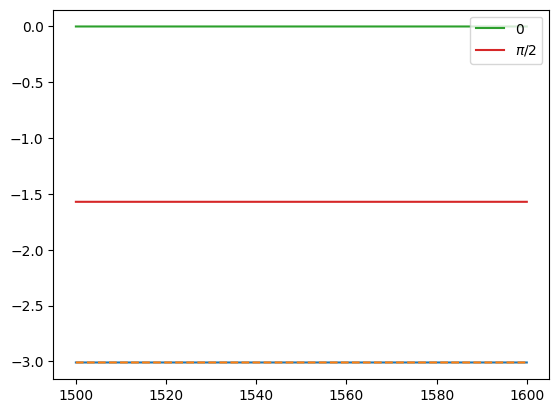

In [4]:
lamb = np.linspace(1500e-9,1600e-9,100000)

In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
result = C @ In
Ao = result[0][0]*np.ones_like(lamb)
Bo = result[1][0]*np.ones_like(lamb)

T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)), ls = "--")
plt.plot(lamb*1e9,np.angle(Ao), label = "$0$")
plt.plot(lamb*1e9,np.angle(Bo), label = r"$\pi/2$")
plt.legend()

# Y-Branch

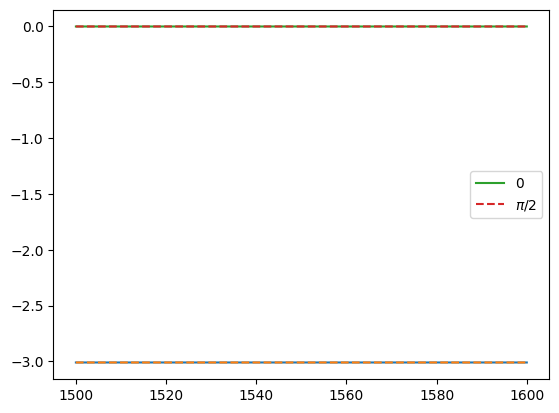

In [5]:

In = np.array([[1]],dtype=complex)

Y = np.array([[1/np.sqrt(2)],[1/np.sqrt(2)]])

result = Y@ In
Ao = result[0][0]*np.ones_like(lamb)
Bo = result[1][0]*np.ones_like(lamb)

T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)), ls = "--")
plt.plot(lamb*1e9,np.angle(Ao), label = "$0$")
plt.plot(lamb*1e9,np.angle(Bo), label = r"$\pi/2$", ls = "--")
plt.legend()

In [6]:
lamb = np.linspace(1500e-9,1600e-9,100000)

neff0 = 2.3537
ng = 2.3537
FSR_nm = 20e-9
l0 = 300e-6
delta_L = (lambda0**2)/(ng*FSR_nm)

Beta = Beta_calc(ng, neff0, lambda0, lamb)
print(delta_L)

5.103666567531971e-05


# Waveguide

(-5.0, 5.0)

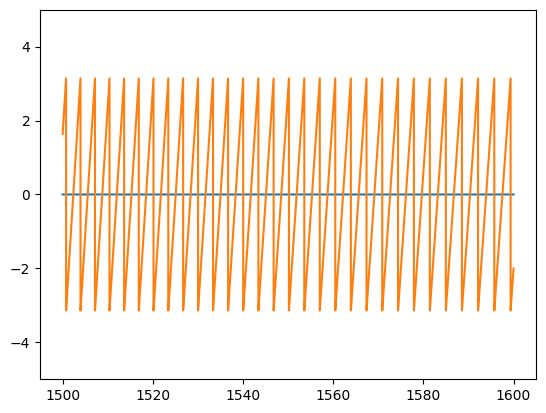

In [7]:
In = np.array([[1]])
wvg = WVG(Beta,L=l0)

wvg = wvg@In

Ao = wvg[:,0,0]

T5 = np.abs(Ao)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.plot(lamb*1e9,np.angle(Ao))
plt.ylim(-5,5)


# MZI

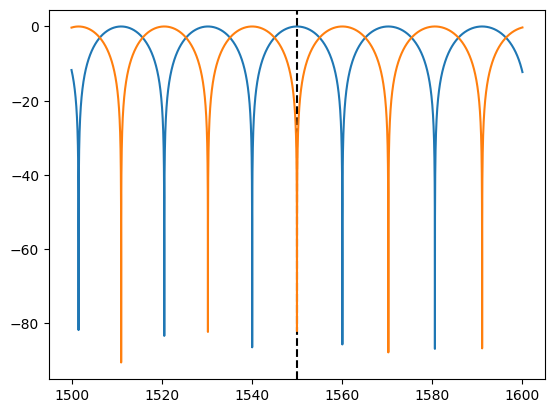

In [8]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
ARMS = ARMS_FOR_MZI(Beta,l0,delta_L)
MZI = C @ ARMS @ C @ In

Ao = MZI[:,0,0]
Bo = MZI[:,1,0]
T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)))



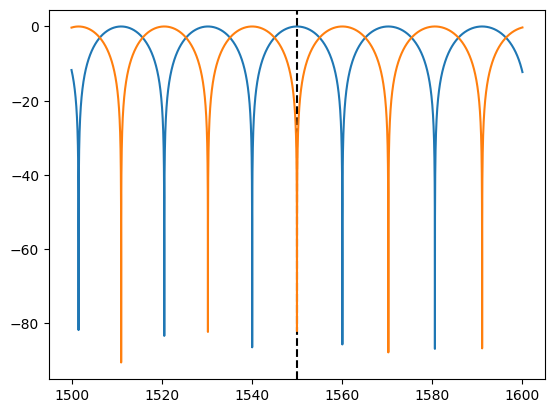

In [9]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))

WVG1 = WVG(Beta,l0 + delta_L/2)
WVG2 = WVG(Beta,l0 - delta_L/2)
ARMS = np.zeros((len(Beta), 2, 2), dtype=complex)
ARMS[:,0,0] = WVG1[:,0,0]
ARMS[:,1,1] = WVG2[:,0,0]

MZI = C @ ARMS @ C @ In

Ao = MZI[:,0,0]
Bo = MZI[:,1,0]
T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)))



# Micro-Ring Resonator (MRR)

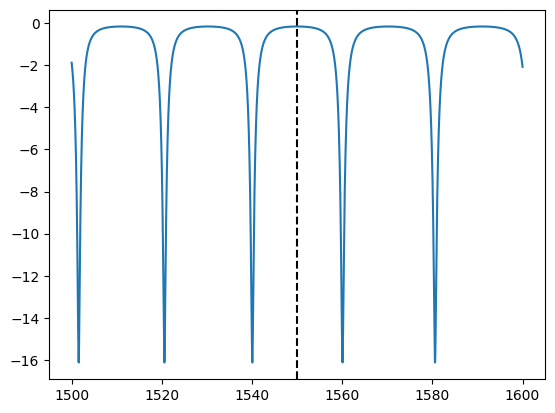

In [10]:
In = np.array([[1]])
r = 0.85
mrr = MRR(Beta,L=delta_L,a=0.8,r=r)

mrr = mrr@In

Ao = mrr[:,0,0]

T5 = np.abs(Ao)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")

# Ring Resonator

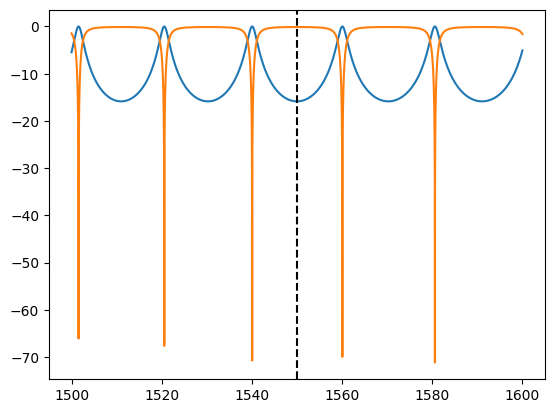

In [11]:
In = np.array([[1],[0]])

r1 = r2 = 0.85
rr = RR(Beta,L=delta_L,a=1,r1=r1,r2=r2)

rr = rr@In

Ao = rr[:,0,0]
Bo = rr[:,1,0]

T5 = np.abs(Ao)**2
T6 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.plot(lamb*1e9,10*np.log10(T6))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")

# RAMZI

In [12]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
first = C @ In

mrr = MRR(Beta,L=delta_L*2,a=0.8,r=1/np.sqrt(2))
wvg = WVG(Beta,L=delta_L*4)

A1 = np.ones((len(Beta),1,1),dtype=complex)*first[0,0]
B1 = np.ones((len(Beta),1,1),dtype=complex)*first[1,0]

A2 = mrr@A1
B2 = wvg@B1

aux1 = np.ones((len(Beta),2,1),dtype=complex)
aux1[:,0,0] = A2[:,0,0]
aux1[:,1,0] = B2[:,0,0]

Out = C @ aux1

Ao = Out[:,0,0]
Bo = Out[:,1,0]

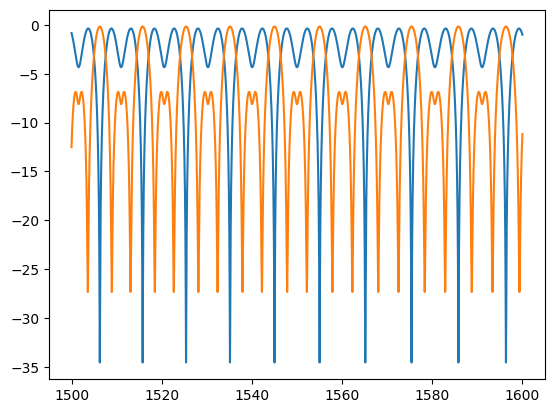

In [13]:
plt.plot(lamb*1e9,10*np.log10(np.abs(Ao)**2))
plt.plot(lamb*1e9,10*np.log10(np.abs(Bo)**2))

# D-RAMZI

In [14]:
In = np.ones((len(Beta),1,1),dtype=complex)

Y_splitter = np.array([[1/np.sqrt(2)],[1/np.sqrt(2)]])

C = DC(1/np.sqrt(2))

L_rr_1 = delta_L*2
L_rr_2 = delta_L*2

L_wvg1 = delta_L*4
L_wvg2 = 50e-6 + delta_L*2
L_wvg3 = 50e-6
L_wvg4 = delta_L*4
L_wvg5 = 50e-6
L_wvg6 = 50e-6 + delta_L*2

SOA = 2


In [15]:

mrr1 = MRR(Beta,L=L_rr_1,a=0.8,r=1/np.sqrt(2))
wvg1 = WVG(Beta,L=L_wvg1)
RAMZI1 = np.zeros((len(Beta),2,2),dtype=complex)
RAMZI1[:,0,0] = mrr1[:,0,0]
RAMZI1[:,1,1] = wvg1[:,0,0]

wvg2 = WVG(Beta,L=L_wvg2)
wvg3 = WVG(Beta,L=L_wvg3)
MZI1 = np.zeros((len(Beta), 2, 2), dtype=complex)
MZI1[:,0,0] = wvg2[:,0,0]
MZI1[:,1,1] = wvg3[:,0,0]

out1 = MZI1 @ C @ RAMZI1 @ Y_splitter @ In

out1 = out1[:,0,0]*1/np.sqrt(2) + out1[:,1,0]*1/np.sqrt(2) 
OUT1 = np.zeros((len(Beta),1,1),dtype=complex)
OUT1[:,0,0] = out1  

######################################################################################

In2 = OUT1 * SOA 

######################################################################################

mrr2 = MRR(Beta,L=L_rr_2,a=0.8,r=1/np.sqrt(2))
wvg4 = WVG(Beta,L=L_wvg4)
RAMZI2 = np.zeros((len(Beta),2,2),dtype=complex)
RAMZI2[:,0,0] = mrr2[:,0,0]
RAMZI2[:,1,1] = wvg4[:,0,0]

wvg5 = WVG(Beta,L=L_wvg5)
wvg6 = WVG(Beta,L=L_wvg6)
MZI2 = np.zeros((len(Beta), 2, 2), dtype=complex)
MZI2[:,0,0] = wvg5[:,0,0]
MZI2[:,1,1] = wvg6[:,0,0]

out2 = MZI2 @ C @ RAMZI2 @ Y_splitter @ In2

out2 = out2[:,0,0]*1/np.sqrt(2) + out2[:,1,0]*1/np.sqrt(2) 


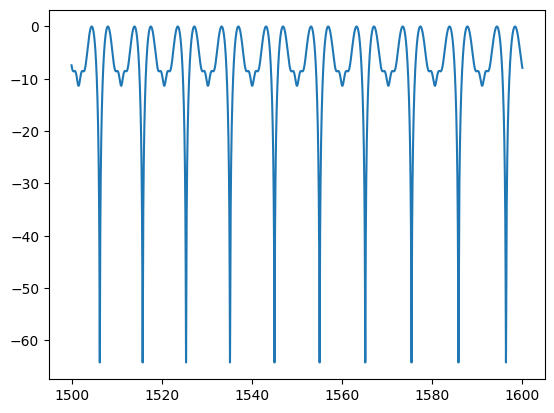

In [16]:
norm = np.abs(out2)/max(np.abs(out2))
plt.plot(lamb*1e9,10*np.log10(norm**2))


# Testes

Dúvida 2, quanto a variação de $n_{eff}$: Conforme a potência, $P_{in}$, é aplicada, a dispersão de portadores livres provoca a mudança do número de portadores, $N_c$, ou seja, o índice de refração é alterado. Como que $N_c$ entra no cálculo de $n_{eff}$? 

Dúvida 3, quanto a dinâmica não-linear: Se $n_{eff}$ é alterado, então o espectro óptico do MRR é shiftado. A dinâmica então é: Para cada $N_c$ ($P_{in}$), em um comprimento de onda qualquer, $\lambda$, o espectro do MRR é shiftado, de tal forma que o comprimento de onda de ressonância do MRR, $\lambda_{res}$, dança em torno de $\lambda$. Ou seja, a potência de saída, $P_{out}$, em $\lambda$ também dança, apresentando os comportamentos vistos em Fig. 1 (c).

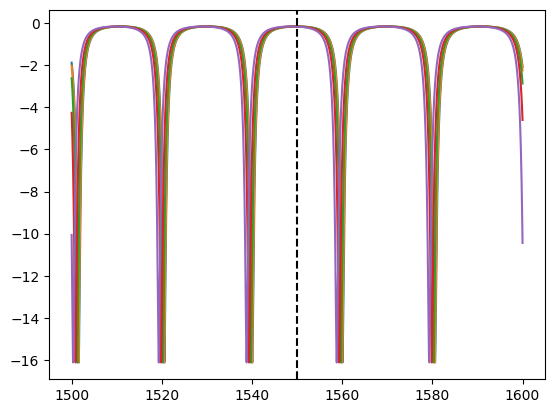

In [17]:
In = np.array([[1]])
r = 0.85
for i,NC_SS in enumerate(Nc_ss):
    Beta = Beta_MRR(ng, neff0,lambda0,lamb,NC_SS,eta_fc)
    mrr = MRR(Beta,L=delta_L,a=0.8,r=r)

    mrr = mrr@In

    Ao = mrr[:,0,0]

    T5 = np.abs(Ao)**2

    if (i%200 == 0):
        plt.plot(lamb*1e9,10*np.log10(T5)) 
    
plt.axvline(x=lambda0*1e9, ls = "--", c="k")
plt.show()

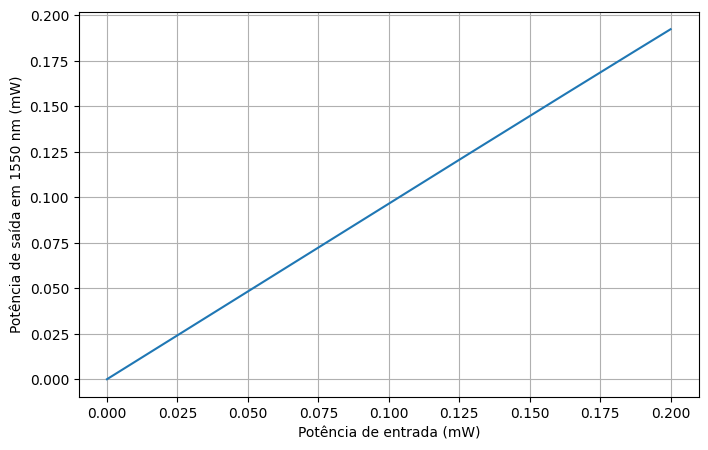

In [18]:
lambda_laser = 1550e-9

P_out = []

for P, Nc in zip(P_vec, Nc_ss):

    Beta = Beta_MRR(
        ng,
        neff0,
        lambda0,
        np.array([lambda_laser]),
        Nc,
        eta_fc
    )

    mrr = MRR(
        Beta,
        L=delta_L,
        a=0.8,
        r=0.85
    )

    T = np.abs(mrr[0,0,0])**2

    P_out.append(T * P)

P_out = np.array(P_out)

plt.figure(figsize=(8,5))
plt.plot(P_vec*1e3, P_out*1e3)

plt.xlabel("Potência de entrada (mW)")
plt.ylabel("Potência de saída em 1550 nm (mW)")
plt.grid()
plt.show()

Dúvida 4, quanto a geração dos 9 gráficos da Fig. 1(c): Quais parâmetros devem ser variados para observar aqueles comportamentos? Qual os comprimentos de cada estrutura ($L_{ring}$, $\Delta_{L}$, ...)?


In [19]:
# ============================================================
# DINÂMICA DOS PORTADORES
# ============================================================

def carrier_dynamics(t, y, Pin, delta_omega):

    a_real, a_imag, Nc = y

    a_cav = a_real + 1j*a_imag
    intensity = np.abs(a_cav)**2

    da_dt = (-(1j*delta_omega + gamma)*a_cav- 1j*eta_fc*Nc*a_cav- 1j*mu*np.sqrt(Pin))
    dNc_dt = (-Nc/tau+ xi*intensity**2)

    return [da_dt.real,da_dt.imag,dNc_dt]


# ============================================================
# ESTADO ESTACIONÁRIO
# ============================================================

    
def get_Nc_ss(Pin, delta_omega):

    sol = solve_ivp(lambda t, y: carrier_dynamics(t, y, Pin,delta_omega),(0, 100e-9),[0.0, 0.0, 0.0],rtol=1e-9,atol=[1e-20,1e-20,1e-14],method="DOP853")

    Nc = sol.y[2, -1]

    return Nc


# ============================================================
# RAMZI
# ============================================================


C = DC(1/np.sqrt(2))
Y_splitter = np.array([[1/np.sqrt(2)],[1/np.sqrt(2)]])

def RAMZI(Nc, vec_lamb, alpha_eff,delta_phi=0):

    Ein = np.array([[1]], dtype=complex)

    beta_wvg = Beta_calc(ng, neff0,lambda0,vec_lamb)
    beta_ring = Beta_MRR(ng, neff0,lambda0,vec_lamb,Nc,eta_fc)

    mrr1 = MRR(beta_ring,L=L_rr_1,a=alpha_eff,r=1/np.sqrt(2))
    wvg1 = WVG(beta_wvg, L=L_wvg1)
    RAMZI1 = np.zeros((len(vec_lamb),2,2),dtype=complex)
    RAMZI1[:,0,0] = mrr1[:,0,0]
    RAMZI1[:,1,1] = wvg1[:,0,0]

    phase_matrix = np.array([
        [1, 0],
        [0, np.exp(1j*delta_phi)]
    ], dtype=complex)

    Out = C @ phase_matrix @ RAMZI1 @ Y_splitter @ Ein

    T = np.abs(Out[:, 0, 0])**2

    return T

In [20]:
np.random.seed(100)
delta_random = np.random.uniform(0, 2*np.pi,9)
alfa_random = np.random.uniform(0.75, 0.95,9)
print(delta_random)

[3.41431395 1.74904643 2.66732269 5.30788498 0.02964945 0.76384131
 4.21444079 5.1889859  0.85895284]


In [21]:
configs = [(alfa_random[i], delta_random[i]) for i in range(9)]

df = pd.DataFrame(configs, columns=["alfa", "delta (rad/s)"])

df["delta (rad/s)"] = df["delta (rad/s)"].map(lambda x: f"  {x:.4f}")

print(df.to_string(index=False))

    alfa delta (rad/s)
0.865019        3.4143
0.928264        1.7490
0.791840        2.6673
0.787066        5.3079
0.771675        0.0296
0.793939        0.7638
0.945725        4.2144
0.912337        5.1890
0.784388        0.8590


C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:13: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:10: RuntimeWarning: overflow encountered in scalar power
  intensity = np.abs(a_cav)**2
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:12: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j*delta_omega + gamma)*a_cav- 1j*eta_fc*Nc*a_cav- 1j*mu*np.sqrt(Pin))
c:\Users\erick.sousa\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\integrate\_ivp\rk.py:684: RuntimeWarning: invalid value encountered in dot
  err5 = np.dot(K.T, self.E5) / scale
c:\Users\erick.sousa\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\integrate\_ivp\rk.py:685: RuntimeWarning: invalid value encountered in dot
  err3 = np.dot(K.T, self.E3) / scale
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:1

KeyboardInterrupt: 

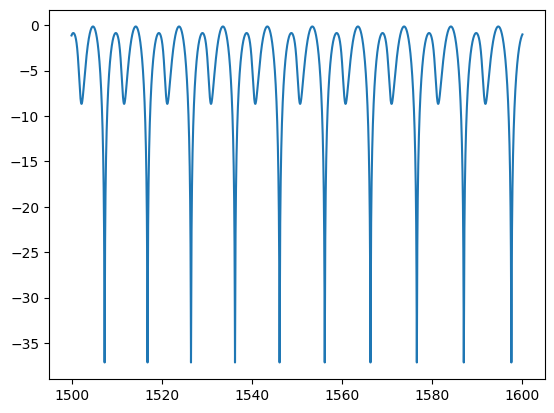

In [22]:
for alpha_eff, delta_phi in configs:

    for i,Pin in enumerate(P_vec):

        # 1. Portadores
        Nc = get_Nc_ss(Pin,delta)

        # 2. RAMZI
        T = RAMZI(Nc,np.array(lamb),alpha_eff,delta_phi)

        if (i%200==0):
            plt.plot(lamb*1e9, 10*np.log10(T))
    plt.xlim(1548,1552)
    plt.axvline(1550)
    plt.show()

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:10: RuntimeWarning: overflow encountered in scalar power
  intensity = np.abs(a_cav)**2
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:12: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j*delta_omega + gamma)*a_cav- 1j*eta_fc*Nc*a_cav- 1j*mu*np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  da

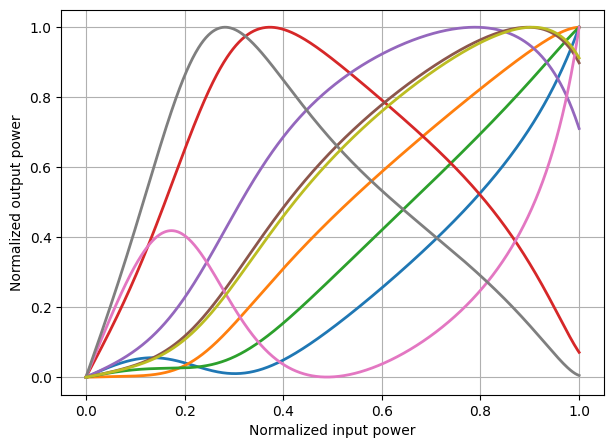

In [ ]:
plt.figure(figsize=(7, 5))

for alpha_eff, delta_phi in configs:

    Pout = []

    for Pin in P_vec:

        # 1. Portadores
        Nc = get_Nc_ss(Pin,delta)

        # 2. RAMZI
        T = RAMZI(Nc,np.array([lambda0]),alpha_eff,delta_phi)

        # 3. potência
        Pout.append(Pin*T)

    Pout = np.array(Pout)
    # normalização
    Pin_norm = P_vec / np.max(P_vec)
    Pout_norm = Pout / np.max(Pout)

    plt.plot(Pin_norm,Pout_norm,lw=2)

plt.xlabel("Normalized input power")
plt.ylabel("Normalized output power")
plt.grid(True)
plt.show()

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:10: RuntimeWarning: overflow encountered in scalar power
  intensity = np.abs(a_cav)**2
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:12: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j*delta_omega + gamma)*a_cav- 1j*eta_fc*Nc*a_cav- 1j*mu*np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:13: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_6852\823802008.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  da

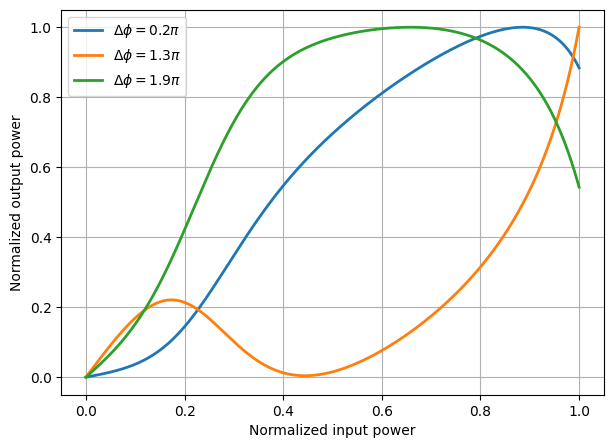

In [ ]:
delta_phis = [
    0.2*np.pi,
    1.3*np.pi,
    1.9*np.pi
]
alpha_eff, delta_phi = configs[0][0], configs[0][1]

plt.figure(figsize=(7,5))

for delta_phi in delta_phis:

    Pout = []

    for i, Pin in enumerate(P_vec):

        Nc = get_Nc_ss(Pin,delta)

        T = RAMZI(Nc=Nc,vec_lamb=np.array([lambda0]),alpha_eff=alpha_eff,delta_phi=delta_phi)

        Pout.append(Pin*T)

    Pout = np.array(Pout)

    Pin_norm = P_vec / np.max(P_vec)
    Pout_norm = Pout / np.max(Pout)

    plt.plot(Pin_norm,Pout_norm,lw=2,label=rf"$\Delta\phi={delta_phi/np.pi:.1f}\pi$")


plt.xlabel("Normalized input power")
plt.ylabel("Normalized output power")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def D_RAMZI(Nc, vec_lamb, alpha_eff,delta_phi=0):

    Ein = np.array([[1]], dtype=complex)

    beta_wvg = Beta_calc(ng, neff0,lambda0,vec_lamb)
    beta_ring = Beta_MRR(ng, neff0,lambda0,vec_lamb,Nc,eta_fc)
    
    phase_matrix = np.array([
        [1, 0],
        [0, np.exp(1j*delta_phi)]
        ], dtype=complex)
    
    mrr1 = MRR(beta_ring,L=L_rr_1,a=alpha_eff,r=1/np.sqrt(2))
    wvg1 = WVG(beta_wvg, L=L_wvg1)
    wvg2 = WVG(beta_wvg, L=L_wvg2)
    wvg3 = WVG(beta_wvg, L=L_wvg3)

    RAMZI1 = np.zeros((len(vec_lamb),2,2),dtype=complex)
    RAMZI1[:,0,0] = mrr1[:,0,0]
    RAMZI1[:,1,1] = wvg1[:,0,0]

    MZI1 = np.zeros((len(vec_lamb),2,2),dtype=complex)
    MZI1[:,0,0] = wvg2[:,0,0]
    MZI1[:,1,1] = wvg3[:,0,0]

    out1 = phase_matrix @ MZI1 @ C @ phase_matrix @ RAMZI1 @ Y_splitter @ Ein

    out1 = out1[:,0,0]*1/np.sqrt(2) + out1[:,1,0]*1/np.sqrt(2) 
    OUT1 = np.zeros((len(Beta),1,1),dtype=complex)
    OUT1[:,0,0] = out1  

    ######################################################################################

    In2 = OUT1 * SOA 

    ######################################################################################

    mrr2 = MRR(beta_ring,L=L_rr_2,a=0.8,r=1/np.sqrt(2))
    wvg4 = WVG(beta_wvg,L=L_wvg4)
    wvg5 = WVG(beta_wvg,L=L_wvg5)
    wvg6 = WVG(beta_wvg,L=L_wvg6)

    RAMZI2 = np.zeros((len(Beta),2,2),dtype=complex)
    RAMZI2[:,0,0] = mrr2[:,0,0]
    RAMZI2[:,1,1] = wvg4[:,0,0]

    MZI2 = np.zeros((len(vec_lamb),2,2),dtype=complex)
    MZI2[:,0,0] = wvg5[:,0,0]
    MZI2[:,1,1] = wvg6[:,0,0]

    out2 = phase_matrix @ MZI2 @ C @ phase_matrix @ RAMZI2 @ Y_splitter @ In2

    out2 = out2[:,0,0]*1/np.sqrt(2) + out2[:,1,0]*1/np.sqrt(2) 

    T = np.abs(out2)**2

    return T

In [ ]:
alpha_eff, delta_phi = configs[0][0], configs[0][1]

plt.figure(figsize=(7,5))

for delta_phi in delta_phis:

    Pout = []

    for i, Pin in enumerate(P_vec):

        Nc = get_Nc_ss(Pin,delta)

        T = D_RAMZI(Nc=Nc,vec_lamb=np.array([lambda0]),alpha_eff=alpha_eff,delta_phi=delta_phi)

        Pout.append(Pin*T)

    Pout = np.array(Pout)

    Pin_norm = P_vec / np.max(P_vec)
    Pout_norm = Pout / np.max(Pout)

    plt.plot(Pin_norm,Pout_norm,lw=2,label=rf"$\Delta\phi={delta_phi/np.pi:.1f}\pi$")


plt.xlabel("Normalized input power")
plt.ylabel("Normalized output power")

plt.legend()
plt.grid(True)

plt.show()

TypeError: D_RAMZI() got an unexpected keyword argument 'Nc'

<Figure size 700x500 with 0 Axes>

In [23]:
def PHASE(phi):

    return np.array([
        [1, 0],
        [0, np.exp(1j * phi)]
    ], dtype=complex)

def D_RAMZI(
    Pin,
    vec_lamb,

    # parâmetros do RAMZI 1
    alpha1,
    phi_1a,
    phi_1b,

    # parâmetros do RAMZI 2
    alpha2,
    phi_2a,
    phi_2b,

    # ganho do SOA
    G_SOA,

    # detuning dos dois MRRs
    delta_omega1,
    delta_omega2
):

    # --------------------------------------------------------
    # Entrada óptica
    #
    # Assumimos:
    #
    # P = |E|²
    #
    # portanto:
    #
    # E = sqrt(P)
    # --------------------------------------------------------

    Ein = np.array(
        [[np.sqrt(Pin)]],
        dtype=complex
    )


    # ========================================================
    # RAMZI 1
    # ========================================================

    # --------------------------------------------------------
    # 1. Carrier density do primeiro MRR
    # --------------------------------------------------------

    Nc1 = get_Nc_ss(
        Pin,
        delta_omega1
    )


    # --------------------------------------------------------
    # 2. Beta do waveguide
    # --------------------------------------------------------

    beta_wvg = Beta_calc(
        ng,
        neff0,
        lambda0,
        vec_lamb
    )


    # --------------------------------------------------------
    # 3. Beta do primeiro MRR
    # --------------------------------------------------------

    beta_ring1 = Beta_MRR(
        ng,
        neff0,
        lambda0,
        vec_lamb,
        Nc1,
        eta_fc
    )


    # --------------------------------------------------------
    # 4. Primeiro MRR
    # --------------------------------------------------------

    mrr1 = MRR(
        beta_ring1,
        L=L_rr_1,
        a=alpha1,
        r=1 / np.sqrt(2)
    )


    # --------------------------------------------------------
    # 5. Waveguide do primeiro RAMZI
    # --------------------------------------------------------

    wvg1 = WVG(
        beta_wvg,
        L=L_wvg1
    )


    # --------------------------------------------------------
    # 6. Matriz do primeiro RAMZI
    # --------------------------------------------------------

    RAMZI1 = np.zeros(
        (len(vec_lamb), 2, 2),
        dtype=complex
    )

    RAMZI1[:, 0, 0] = mrr1[:, 0, 0]
    RAMZI1[:, 1, 1] = wvg1[:, 0, 0]


    # --------------------------------------------------------
    # 7. MZI depois do MRR
    # --------------------------------------------------------

    wvg2 = WVG(
        beta_wvg,
        L=L_wvg2
    )

    wvg3 = WVG(
        beta_wvg,
        L=L_wvg3
    )

    MZI1 = np.zeros(
        (len(vec_lamb), 2, 2),
        dtype=complex
    )

    MZI1[:, 0, 0] = wvg2[:, 0, 0]
    MZI1[:, 1, 1] = wvg3[:, 0, 0]


    # --------------------------------------------------------
    # 8. Phase shifters independentes
    # --------------------------------------------------------

    Phase_1a = PHASE(phi_1a)
    Phase_1b = PHASE(phi_1b)


    # --------------------------------------------------------
    # 9. Propagação pelo RAMZI 1
    # --------------------------------------------------------

    out1 = (
        Phase_1b
        @ MZI1
        @ C
        @ Phase_1a
        @ RAMZI1
        @ Y_splitter
        @ Ein
    )


    # --------------------------------------------------------
    # 10. Combinação das duas componentes de saída
    # --------------------------------------------------------

    E1 = (
        out1[:, 0, 0] / np.sqrt(2)
        +
        out1[:, 1, 0] / np.sqrt(2)
    )


    # ========================================================
    # SOA
    # ========================================================

    # Aqui G_SOA é interpretado como GANHO DE POTÊNCIA.
    #
    # Portanto:
    #
    # E_out = sqrt(G) * E_in
    #
    # Se o seu SOA estiver definido como ganho de CAMPO,
    # essa linha deverá ser alterada.
    # ========================================================

    E2 = np.sqrt(G_SOA) * E1


    # ========================================================
    # POTÊNCIA NA ENTRADA DO RAMZI 2
    # ========================================================

    Pin2 = np.abs(E2)**2


    # ========================================================
    # RAMZI 2
    # ========================================================

    # --------------------------------------------------------
    # 11. Carrier density do segundo MRR
    # --------------------------------------------------------
    Nc2 = get_Nc_ss(
        Pin2[0],
        delta_omega2
    )


    # --------------------------------------------------------
    # 12. Beta do segundo MRR
    # --------------------------------------------------------

    beta_ring2 = Beta_MRR(
        ng,
        neff0,
        lambda0,
        vec_lamb,
        Nc2,
        eta_fc
    )


    # --------------------------------------------------------
    # 13. Segundo MRR
    # --------------------------------------------------------

    mrr2 = MRR(
        beta_ring2,
        L=L_rr_2,
        a=alpha2,
        r=1 / np.sqrt(2)
    )


    # --------------------------------------------------------
    # 14. Waveguide do segundo RAMZI
    # --------------------------------------------------------

    wvg4 = WVG(
        beta_wvg,
        L=L_wvg4
    )


    # --------------------------------------------------------
    # 15. Matriz do segundo RAMZI
    # --------------------------------------------------------

    RAMZI2 = np.zeros(
        (len(vec_lamb), 2, 2),
        dtype=complex
    )

    RAMZI2[:, 0, 0] = mrr2[:, 0, 0]
    RAMZI2[:, 1, 1] = wvg4[:, 0, 0]


    # --------------------------------------------------------
    # 16. MZI do segundo RAMZI
    # --------------------------------------------------------

    wvg5 = WVG(
        beta_wvg,
        L=L_wvg5
    )

    wvg6 = WVG(
        beta_wvg,
        L=L_wvg6
    )

    MZI2 = np.zeros(
        (len(vec_lamb), 2, 2),
        dtype=complex
    )

    MZI2[:, 0, 0] = wvg5[:, 0, 0]
    MZI2[:, 1, 1] = wvg6[:, 0, 0]


    # --------------------------------------------------------
    # 17. Phase shifters independentes
    # --------------------------------------------------------

    Phase_2a = PHASE(phi_2a)
    Phase_2b = PHASE(phi_2b)


    # --------------------------------------------------------
    # 18. Propagação pelo RAMZI 2
    # --------------------------------------------------------

    # Transformamos E2 em matriz [Nlambda, 1, 1]

    In2 = E2[:, None, None]


    out2 = (
        Phase_2b
        @ MZI2
        @ C
        @ Phase_2a
        @ RAMZI2
        @ Y_splitter
        @ In2
    )


    # --------------------------------------------------------
    # 19. Saída óptica
    # --------------------------------------------------------

    Eout = (
        out2[:, 0, 0] / np.sqrt(2)
        +
        out2[:, 1, 0] / np.sqrt(2)
    )


    # --------------------------------------------------------
    # 20. Potência de saída
    # --------------------------------------------------------

    Pout = np.abs(Eout)**2


    return Pout

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:13: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:10: RuntimeWarning: overflow encountered in scalar power
  intensity = np.abs(a_cav)**2
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:13: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:13: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc/tau+ xi*intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:12: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j*delta_omega + gamma)*a_cav- 1j*eta_fc*Nc*a_cav- 1j*mu*np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_16824\823802008.py:12: RuntimeWarning: invalid value encountered in scalar multipl

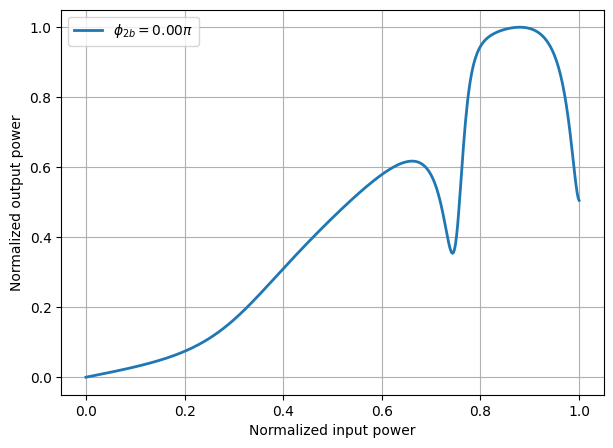

In [28]:
# ============================================================
# TESTE 1 — Efeito de delta_phi
# ============================================================

# Mantemos todos os parâmetros fixos
alpha1 = 0.80
alpha2 = 0.80

phi_1a = np.array([
    0,
    0.25*np.pi,
    0.50*np.pi,
    0.75*np.pi,
    1.00*np.pi,
    1.25*np.pi,
    1.50*np.pi,
    1.75*np.pi,
    2.00*np.pi
])

phi_1b = np.array([
    0,
    0.25*np.pi,
    0.50*np.pi,
    0.75*np.pi,
    1.00*np.pi,
    1.25*np.pi,
    1.50*np.pi,
    1.75*np.pi,
    2.00*np.pi
])

phi_2a = np.array([
    0,
    0.25*np.pi,
    0.50*np.pi,
    0.75*np.pi,
    1.00*np.pi,
    1.25*np.pi,
    1.50*np.pi,
    1.75*np.pi,
    2.00*np.pi
])

G_SOA = 4

# Valores de phi_2b que queremos testar
phi_2b = np.array([
    0,
    0.25*np.pi,
    0.50*np.pi,
    0.75*np.pi,
    1.00*np.pi,
    1.25*np.pi,
    1.50*np.pi,
    1.75*np.pi,
    2.00*np.pi
])

# ------------------------------------------------------------
# Potência de entrada
# ------------------------------------------------------------

P_vec = np.linspace(
    1e-12,
    0.2e-3,
    500
)


plt.figure(figsize=(7, 5))


# ============================================================
# Varre delta_phi
# ============================================================

# for PHI_1A in phi_1a:

Pout = []

for Pin in P_vec:

    # ----------------------------------------------------
    # O D_RAMZI agora calcula:
    #
    # Pin -> Nc1 -> RAMZI1 -> SOA
    #     -> Pin2 -> Nc2 -> RAMZI2 -> Pout
    # ----------------------------------------------------

    Pout_value = D_RAMZI(

        Pin=Pin,

        vec_lamb=np.array([lambda0]),

        # RAMZI 1
        alpha1=alpha1,
        phi_1a=phi_1a[7],
        phi_1b=phi_1b[7],

        # RAMZI 2
        alpha2=alpha2,
        phi_2a=phi_2a[7],
        phi_2b=phi_2b[7],

        # SOA
        G_SOA=G_SOA,

        # Detunings
        delta_omega1=delta,
        delta_omega2=delta
    )

    Pout.append(Pout_value[0])


Pout = np.array(Pout)


# --------------------------------------------------------
# Normalização
# --------------------------------------------------------

Pin_norm = P_vec / np.max(P_vec)
Pout_norm = Pout / np.max(Pout)


# --------------------------------------------------------
# Gráfico
# --------------------------------------------------------

plt.plot(
    Pin_norm,
    Pout_norm,
    lw=2,
    label=rf"$\phi_{{2b}}={phi_1a[0]/np.pi:.2f}\pi$"
)


plt.xlabel("Normalized input power")
plt.ylabel("Normalized output power")

plt.legend()
plt.grid(True)

plt.show()